# Prompt 09: extensions (pass 1: sections 1-4)

**Status:** pass 1 run 2026-11-07. Drivers: `code/R/09a_fang_crosscheck.R`, `09b_by_type.R`, `09c_ai_impact.R`, `09d_national_drivers.R`; tables from `code/python/09_extend_tables.py`. Results: `results/2026-11-07/extend/`. Every model was pre-registered in `EXPERIMENTS.md` section 14 before it ran; deviations X1-X4 are logged there.

**Main spec unless stated:** 50 states, two-way FE, AI(t-1), ctrl4, clustered by state, winsorized 1/99. Two AI measures: private data-center jobs per 1,000 workers (2015-2025) and AI postings per 1,000 workers (lag available 2019-2025). **A finding** needs BH q < 0.10 within its family and a lead (AI(t+1)) that is clearly smaller: |lead| < 0.5 x |lag| and lead p >= 0.10. All results are associations.

Section 5 (a better AI measure) runs in pass 2.

In [1]:
import pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60); pd.set_option('display.max_rows', 120)
T = '../results/2026-11-07/extend/tables/'; F = '../results/2026-11-07/extend/figures/'

## 1. Does our data match Fang's? (no year FE)

**Question:** do our variables and Fang's Table 2 line up, and what do trend tests say about Fang's spec?

**What we ran:** (1) Fang's descriptive statistics (Table A1) are in a supplement that isn't in `literature/`, so we used the means implied by Table 2's constants. With Stata-style FE constants, constant = mean(Y) - sum of b x mean(X); fixing mean ln AI at ours, columns 1-6 solve for the other six means. (2) Table 2 on four outcome bases, plus the archived June 2023 SEDS. (3) Fang's column 6 with a linear trend, and a placebo with ln employment in two non-energy industries whose national growth was closest to postings' 2018-2021 growth (distilleries, pet care; chosen before any regression).

$$\ln ET_{it} = \beta_1 \ln X_{it} + \beta_2 \ln EPU_{it} + \textstyle\sum_k \beta_k \ln CV_{kit} + [\delta\, t] + \alpha_i + \varepsilon_{it},\quad X \in \{AI,\ \text{distillery jobs},\ \text{pet-care jobs}\}$$

,variable,basis,N,mean,sd,min,max,fang_implied_mean,diff,diff_sd,flag,unit_shift_match
0,lnET,current SEDS,204,11.437,1.103,7.722,13.604,11.786,-0.349,-0.316,True,NaN
1,lnET_k26,k = 2.6,204,11.846,1.125,7.896,14.154,11.786,0.060,0.053,False,NaN
2,lnET_rb,rebuilt,204,11.827,1.129,7.888,14.133,11.786,0.041,0.036,False,NaN
3,lnAIp,NaN,204,7.701,1.479,4.543,11.293,7.701,0.000,0.000,False,NaN
4,lnEPU,NaN,204,5.382,0.597,4.100,6.789,5.295,0.087,0.146,False,NaN
5,lnEP,NaN,204,2.927,0.193,2.137,3.487,2.924,0.004,0.019,False,NaN
6,lnGDP,NaN,204,12.350,1.050,10.389,14.969,12.258,0.092,0.088,False,consistent with chained 2012 vs 2017 dollars (expected 0...
7,lnPOP,NaN,204,8.272,1.036,6.354,10.585,8.278,-0.006,-0.006,False,NaN
8,lnEDU,NaN,204,4.232,0.312,3.292,5.284,4.231,0.001,0.002,False,NaN


,ai_measure,term,column,fang_published,current,k_2.6,rebuilt,archived_jun2023,current_fang_inside,rebuilt_fang_inside,archived_jun2023_fang_inside
0,ln AI postings,AI,1,0.0428,-0.0288**,+0.0251*,+0.0149,+0.0346***,no,yes,yes
1,ln AI postings,AI,2,0.0452,-0.0100,+0.0342**,+0.0269*,+0.0435***,no,yes,yes
2,ln AI postings,AI,3,0.0396,-0.0189,+0.0219,+0.0120,+0.0316**,no,yes,yes
3,ln AI postings,AI,4,0.0548,-0.0159,+0.0237,+0.0155,+0.0361**,no,no,yes
4,ln AI postings,AI,5,0.0561,-0.0183,+0.0213,+0.0133,+0.0338*,no,no,yes
5,ln AI postings,AI,6,0.0531,-0.0188,+0.0216,+0.0137,+0.0348*,no,yes,yes
6,ln AI postings,EPU,2,-0.0284,-0.0493***,-0.0240**,-0.0315***,-0.0233**,yes,yes,yes
7,ln AI postings,EPU,3,-0.0206,-0.0370**,-0.0068,-0.0107,-0.0067,yes,yes,yes
8,ln AI postings,EPU,4,-0.0242,-0.0374**,-0.0071,-0.0113,-0.0074,yes,yes,yes
9,ln AI postings,EPU,5,-0.0239,-0.0389**,-0.0086,-0.0126,-0.0089,yes,yes,yes


,block,spec,ai_measure,outcome,term,estimate,se,pval,N
0,trend,fang6,aipostings,lnET,AI,-0.0188,0.0187,0.3172,204
1,trend,fang6trend,aipostings,lnET,AI,-0.0392,0.0289,0.1765,204
2,trend,fang6trend,aipostings,lnET,trend,0.0129,0.0138,0.3540,204
3,trend,fang6,dcjobs,lnET,AI,-0.0655,0.0542,0.2290,204
4,trend,fang6trend,dcjobs,lnET,AI,-0.0668,0.0557,0.2329,204
5,trend,fang6trend,dcjobs,lnET,trend,0.0010,0.0092,0.9166,204
6,trend,fang6,aipostings,lnET_rb,AI,0.0137,0.0202,0.4999,204
7,trend,fang6trend,aipostings,lnET_rb,AI,-0.0555,0.0304,0.0698,204
8,trend,fang6trend,aipostings,lnET_rb,trend,0.0435,0.0145,0.0033,204
9,trend,fang6,dcjobs,lnET_rb,AI,-0.0242,0.0587,0.6813,204


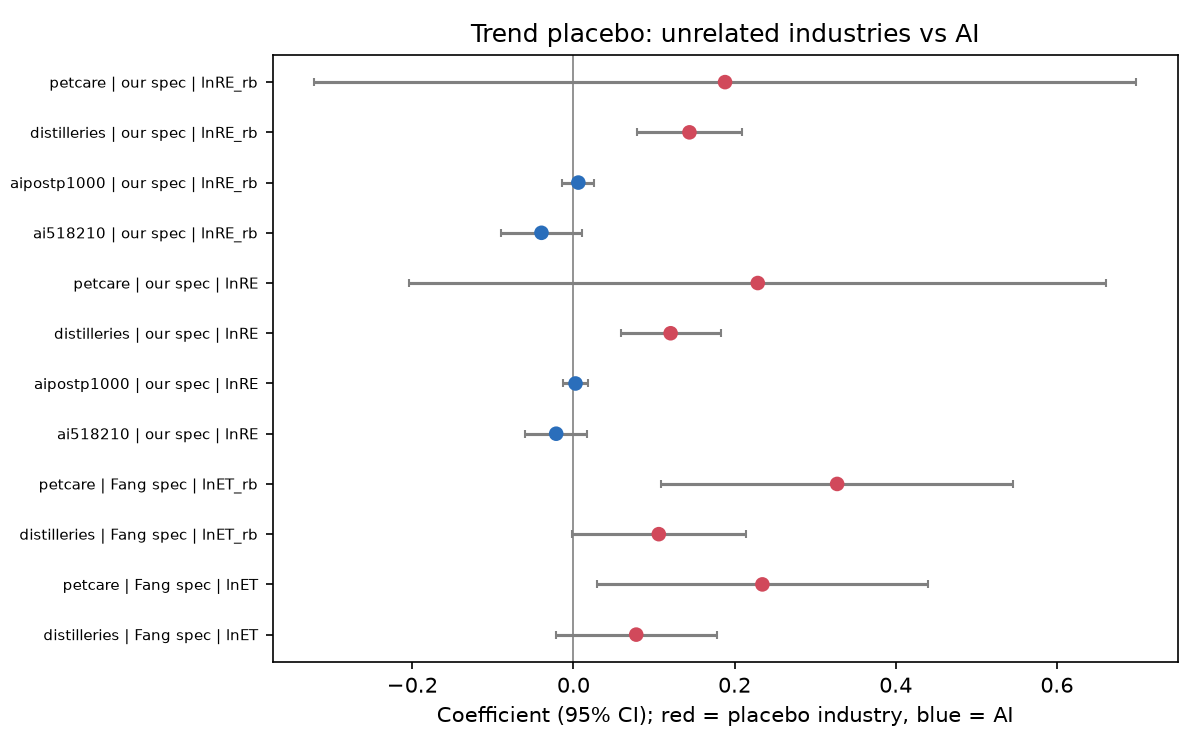

**Verdict.** Our data match Fang's on every regressor. The means implied by Fang's Table 2 constants are within 0.15 SD of ours for EPU, EP, GDP, POP and EDU; GDP's 0.092 gap is consistent with chained 2012 vs 2017 dollars (expected 0.073), and POP matches Fang's stated units (thousands). The outcome is what differs: on current SEDS our mean ln renewables is -0.349 below Fang's implied mean (-0.32 SD, the only flagged row), while on the old fossil-fuel-equivalence basis the gap is 0.041 (rebuilt) and 0.060 (k = 2.6), which is consistent with Fang having used SEDS as published before October 2023. On that June 2023 release, Fang's coefficients fall inside our 95% CIs for 20 of 21 postings-model coefficients, including all six AI coefficients (column 6 AI: +0.0348, p = 0.057, against Fang's +0.0531); the rebuild on today's data is smaller (+0.0137, p = 0.500) because EIA has since revised biomass, and current SEDS flips the sign (-0.0188, p = 0.317). Fang's spec has no year effects, and the trend tests show why that matters: a linear year trend moves the rebuilt-basis postings coefficient to -0.0555 (p = 0.070), and pet-care employment, which has nothing to do with energy, is associated with renewables more strongly than AI is in Fang's spec (+0.3273, p = 0.004). In our two-way FE spec pet care is null (+0.1881, p = 0.462), but distillery employment (N = 298, the state-years where it isn't suppressed) is still significant (+0.1440, p < 0.001), a reminder that year effects remove national trends, not state-specific ones.


In [2]:
ds = pd.read_csv(T + 's1_descriptives_comparison.csv')
display(ds[['variable', 'basis', 'N', 'mean', 'sd', 'min', 'max', 'fang_implied_mean', 'diff', 'diff_sd', 'flag', 'unit_shift_match']].round(3))
t2 = pd.read_csv(T + 's1_table2_four_versions.csv')
display(t2[['ai_measure', 'term', 'column', 'fang_published', 'current', 'k_2.6', 'rebuilt', 'archived_jun2023', 'current_fang_inside', 'rebuilt_fang_inside', 'archived_jun2023_fang_inside']])
tp = pd.read_csv(T + 's1_trend_placebo.csv'); display(tp[['block', 'spec', 'ai_measure', 'outcome', 'term', 'estimate', 'se', 'pval', 'N']].round(4))
display(Image(F + 'fig_s1_trend_placebo.png', width=720))
display(Markdown(open(T + 's1_verdict.md').read()))

**Reading:** our regressors match Fang's within 0.15 SD, and the outcome matches once SEDS is on its pre-October-2023 basis, where Fang's Table 2 reproduces (Fang's AI coefficients sit inside our CIs, though Fang's SEs of 0.015-0.019 make that a loose test).
But Fang's spec has no year effects, and pet-care employment "explains" renewables better than AI does in it, so the positive association there says more about shared trends than about AI.

## 2. Which renewable did AI move? And Georgia

**Question:** is the association concentrated in one renewable type, and is the negative SEDS total really transport biofuels?

**What we ran:** main spec on 19 by-type outcomes x 2 AI measures (family "bytype"; ln geothermal generation couldn't be estimated: 7 states). Shares in levels, ln generation (zeros dropped), MW added per 1,000 MW of 2015 capacity, and SEDS wood/waste, biofuels, and totals without biomass or biofuels. BH q-values across the family; lead placebo for p < 0.10. Small-scale solar isn't in the panel.

$$Y_{st} = \beta\, AI_{s,t-1} + \gamma'\text{ctrl4}_{st} + \mu_s + \tau_t + \varepsilon_{st}$$

,outcome_label,ai,coef,ci95,pval,qval,N,years,lead_placebo,finding,status
0,wind: share of generation,"jobs per 1,000",-0.008413,"[-0.0218, +0.00499]",0.212966,0.662252,550.0,2015-2025,NaN,False,ok
1,wind: share of generation,"postings per 1,000",-0.0007843,"[-0.0051, +0.00353]",0.716230,0.776879,350.0,2019-2025,NaN,False,ok
2,wind: ln generation,"jobs per 1,000",-0.1805**,"[-0.326, -0.0349]",0.016368,0.147316,455.0,2015-2025,lead -0.276 (p=0.016) vs lag -0.191,False,ok
3,wind: ln generation,"postings per 1,000",-0.0477***,"[-0.0775, -0.0179]",0.002390,0.086049,293.0,2019-2025,lead -0.00797 (p=0.681) vs lag -0.0419,True,ok
4,"wind: MW added per 1,000 MW (2015 cap.)","jobs per 1,000",+1.887**,"[+0.39, +3.38]",0.014538,0.147316,550.0,2015-2025,lead +0.799 (p=0.476) vs lag +1.57,False,ok
5,"wind: MW added per 1,000 MW (2015 cap.)","postings per 1,000",+0.5947,"[-1.11, +2.3]",0.485921,0.662252,350.0,2019-2025,NaN,False,ok
6,utility solar: share of generation,"jobs per 1,000",-5.93e-05,"[-0.00606, +0.00594]",0.984238,0.984238,550.0,2015-2025,NaN,False,ok
7,utility solar: share of generation,"postings per 1,000",-0.000975,"[-0.00371, +0.00176]",0.477094,0.662252,350.0,2019-2025,NaN,False,ok
8,utility solar: ln generation,"jobs per 1,000",+0.04204,"[-0.218, +0.302]",0.746152,0.776879,499.0,2015-2025,NaN,False,ok
9,utility solar: ln generation,"postings per 1,000",-0.04603,"[-0.206, +0.114]",0.564995,0.701373,333.0,2019-2025,NaN,False,ok


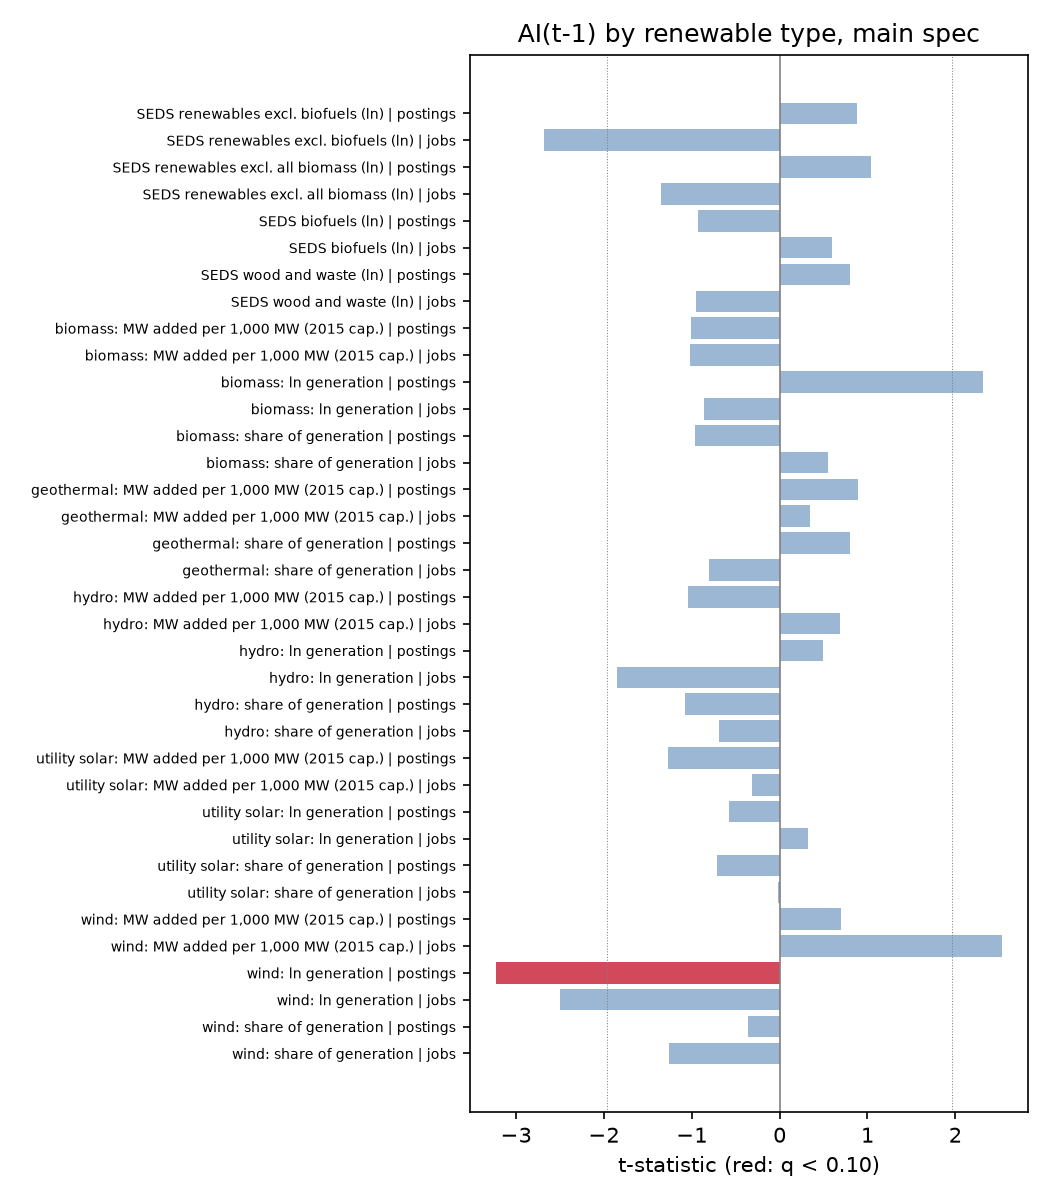

In [3]:
bt = pd.read_csv(T + 's2_bytype_table.csv'); display(bt.drop(columns=['tag', 'note']))
display(Image(F + 'fig_s2_bytype_t.png', width=560))

**Reading:** one row passes the finding rule, and against the expected sign: AI postings are associated with lower ln wind generation (-0.048, q = 0.086, lead -0.008). With data-center jobs the same outcome fails, because its lead is larger than its lag.
Biofuels show nothing (p = 0.55 and 0.36), so the negative SEDS total isn't transport fuel. The only other notable row, renewables without biofuels with jobs (-0.062, q = 0.15), has an equally large lead.

### Georgia

**Profile:** Georgia's data-center jobs per 1,000 rose from 2.01 (rank 22 of 50) in 2015 to 5.04 (rank 3) in 2024, the 2nd-largest increase. Its postings rank is about 19-26. Solar went from 0.1% to 7.7% of in-state generation (2015-2025), with about 5,350 MW of solar added. Georgia has no wind or geothermal generation. Large-load commitments reached 15,600 MW across 32 customers by June 30, 2026 (Q2 2026 Large Load report, Docket 55378, page headers Docket 56002, PDF pp. 5 and 8).

**Implied vs actual:** coefficient x Georgia's change in AI(t-1) (jobs 2015-2025: +3.07 per 1,000; postings 2019-2025: +3.03 per 1,000), with a 95% CI, next to Georgia's actual change over the same years. "At most" uses the CI bound farthest from zero. Not a forecast.

,item,jobs_per1000,jobs_rank_of_50,postings_per1000,postings_rank_of_50
0,"AI level, 2015",2.011,22,NaN,NaN
1,"AI level, 2024",5.044,3,4.167,19.0
2,"AI level, 2025",5.035,2,6.220,25.0
3,AI change (jobs 2015-2024; postings 2018-2024),3.034,2,3.028,26.0


,year,share_wind,share_solar,share_hydro,share_geo,share_bio,share_gas,share_coal,share_nuclear,add_solar_per1000,add_wind_per1000,add_gas_per1000,add_hydro_per1000,add_bio_per1000,renew_share,cap_total_mw,new_solar_mw,new_wind_mw,new_renew_mw
0,2015,0,0.001,0.023,0,0.037,0.392,0.288,0.263,4.421,0,19.575,0.973,4.036,0.061,39045.2,172.6,0,368.2
1,2016,0,0.007,0.025,0,0.034,0.396,0.284,0.259,18.873,0,-0.873,5.404,-0.533,0.066,39753.0,736.9,0,927.1
2,2017,0,0.016,0.019,0,0.039,0.414,0.255,0.264,0.200,0,1.667,0.000,0.246,0.074,39829.7,7.8,0,17.4
3,2018,0,0.015,0.029,0,0.039,0.402,0.249,0.266,1.032,0,0.320,-5.445,1.153,0.083,39657.4,40.3,0,-127.3
4,2019,0,0.017,0.031,0,0.042,0.456,0.196,0.261,12.777,0,6.270,0.000,2.876,0.089,39674.8,498.9,0,611.2
5,2020,0,0.031,0.039,0,0.049,0.493,0.116,0.273,17.482,0,0.031,0.000,-0.169,0.119,40353.8,682.6,0,676.0
6,2021,0,0.039,0.029,0,0.047,0.456,0.154,0.273,22.341,0,0.000,-0.026,-1.094,0.116,41267.4,872.3,0,828.6
7,2022,0,0.055,0.025,0,0.045,0.473,0.133,0.269,14.417,0,-20.730,0.000,-0.602,0.125,39008.8,562.9,0,539.4
8,2023,0,0.058,0.022,0,0.038,0.465,0.130,0.289,12.591,0,14.035,0.000,1.368,0.119,40602.4,491.6,0,545.0
9,2024,0,0.066,0.021,0,0.038,0.407,0.128,0.343,22.535,0,-3.099,0.000,0.136,0.125,42546.3,879.9,0,885.2


,outcome_label,ai_measure,window,implied,implied_lo,implied_hi,actual_change,at_most_share_of_actual
0,wind: share of generation,ai518210,2015-2025,-0.0259,-0.0671,0.0153,0.0000,inf
1,wind: share of generation,aipostp1000,2019-2025,-0.0024,-0.0154,0.0107,0.0000,inf
2,wind: ln generation,ai518210,2015-2025,-0.5550,-1.0028,-0.1072,NaN,NaN
3,wind: ln generation,aipostp1000,2019-2025,-0.1444,-0.2346,-0.0543,NaN,NaN
4,"wind: MW added per 1,000 MW (2015 cap.)",ai518210,2015-2025,5.8007,1.1998,10.4016,0.0000,inf
5,"wind: MW added per 1,000 MW (2015 cap.)",aipostp1000,2019-2025,1.8006,-3.3528,6.9540,0.0000,inf
6,utility solar: share of generation,ai518210,2015-2025,-0.0002,-0.0186,0.0183,0.0758,0.2459
7,utility solar: share of generation,aipostp1000,2019-2025,-0.0030,-0.0112,0.0053,0.0600,0.1872
8,utility solar: ln generation,ai518210,2015-2025,0.1292,-0.6689,0.9274,4.4592,0.2080
9,utility solar: ln generation,aipostp1000,2019-2025,-0.1394,-0.6229,0.3442,1.6443,0.3788


- wind: share of generation (jobs): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: share of generation (postings): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: ln generation (jobs): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: ln generation (postings): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: MW added per 1,000 MW (2015 cap.) (jobs): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- wind: MW added per 1,000 MW (2015 cap.) (postings): Georgia has no wind generation in 2015-2025, so this doesn't apply.
- utility solar: share of generation (jobs): implied -0.000182 (95% CI -0.0186 to +0.0183) against an actual +0.0758 over 2015-2025: at most 25% of Georgia's actual change; the point estimate has the opposite sign.
- utility solar: share of generation (postings): implied -0.00295 (95% CI -0.0112 to +0.00533) against an actual +0.06 over 2019-2025

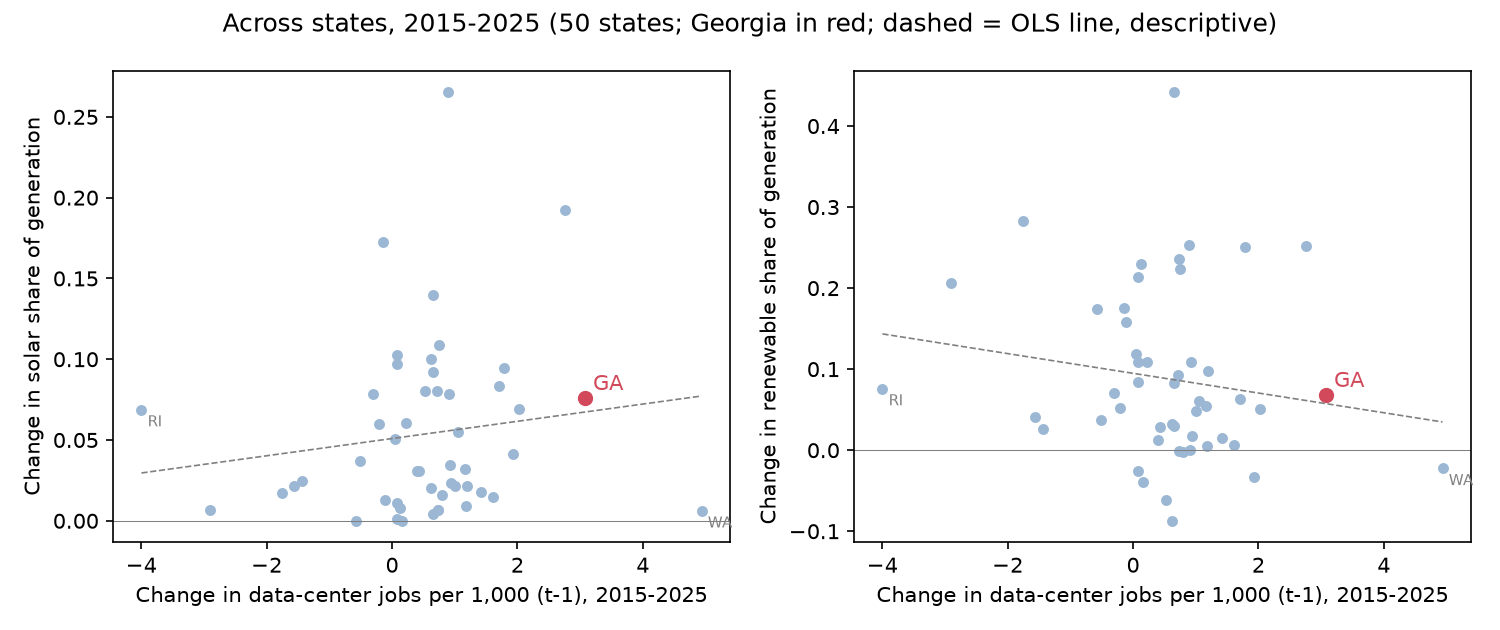

# Georgia Power's plans and large-load growth (prompt 09, section 2.4d)

Sources are only the Georgia PSC documents already in the project (`data/raw/georgia/`); nothing was downloaded. "PDF p." is the page in the PDF file. The latest IRP in the project is the **2025 IRP, Docket No. 56002** (`2025_IRP_Main_Document.pdf`, PDF p. 2), approved by the Commission on July 15, 2025 (`2025_IRP_one_page_summary.pdf`, p. 1). The large-load reports are filed in **Docket No. 55378** (the 2023 IRP Update docket). The Q2 2026 report's cover letter cites both 55378 and 56002 (PDF p. 1), and its page headers carry Docket No. 56002 (PDF pp. 5, 8). A later IRP filing, if one exists, isn't in the project.

## Load growth, and how the plan is tied to it
- Georgia Power projects about **8,200 MW of load growth** from winter 2024/2025 through winter 2030/2031, more than 2,200 MW above the 2023 IRP Update's projection for the same period. It projects nearly 6,000 MW as early as winter 2028/2029 and up to 9,400 MW through winter 2034/2035 (Docket 56002, 2025 IRP, PDF p. 8).
- The forecast includes "specific information for the Company's growing pipeline of potential and committed large load customers" (PDF p. 8). Large load means industrial load of at least 45 MW or commercial load of at least 115 MW (PDF p. 42). Data centers are named among the emerging industries whose growth "accelerated since 2021" (PDF p. 38).
- The plan meets that growth with previously approved RFPs plus incremental requests of up to 1,500 MW "to meet load growth of approximately 8,200 MW through the winter of 2030/2031" (PDF p. 11). The projected capacity-need tables assume the coal extensions below (PDF p. 69).
- **Q2 2026 Large Load report** (filed Aug. 17, 2026, Docket 55378; page headers Docket 56002): commitments reached **15,600 MW across 32 customers**, 8,700 MW of it by winter 2028/2029 (PDF p. 5). Since the October 2023 IRP Update filing, commitments grew from 3,600 MW to 15,600 MW, and the economic-development pipeline from about 17,000 MW to about 84,800 MW through the mid-2030s. About 8,500 MW has broken ground (PDF p. 8, Table 2). In the report's attachment (tab Main), the Data Center/Crypto segment holds 19 projects and 9,149 MW with a Contract for Electric Service, plus 8 projects and 5,811 MW at Request for Service (`data/georgia_large_load_attachment.csv`).

## Coal
- The plan asks for **extended operation of Plant Scherer Unit 3 and Plant Gaston Units 1-4 and A beyond December 31, 2028** (PDF p. 12, request 7). The Company "is not pursuing retirement" of those units by the end of 2028 (PDF p. 19, note 8).
- For **Plant Bowen Units 1-4**, it recommends continued operation, with investment in the required environmental controls (PDF p. 70). Gaston Units 1-4 burn mainly natural gas, with limited coal backup (PDF p. 70).
- Earlier retirements: Plant Wansley Units 1-2 on August 31, 2022 (PDF p. 19).
- 2024 energy for retail customers: 40% natural gas, 16% coal, 29% nuclear, 7% renewables, 2% hydro (PDF p. 15).

## Gas
- More than 2,065 MW of battery storage and combustion-turbine resources by the end of 2027, plus active RFPs for **up to 9,500 MW of capacity** by the end of 2030. An all-source RFP issued in Q3 2025 targets 2032-2033 needs (PDF p. 10).
- Upgrades at existing gas units: Plant McIntosh Units 10-11 (+194 MW by winter 2028/2029) and Units 1A-8A (+74 MW) (PDF p. 66).

## Solar and other renewables
- Active RFPs for more than **3,500 MW of renewable resources by the end of 2030** (PDF p. 10).
- RFPs for energy from **up to 4,000 MW of renewables by 2035**, including a 2026 Utility Scale RFP targeting 1,000 MW in commercial operation between November 30, 2030 and November 30, 2032 (PDF p. 67).

## Storage
- An expedited certification application for **500 MW of Company-owned battery storage** (filed Aug. 16, 2024). The Commission certified the Moody, Robins, Hammond and McGrau Ford Phase II battery projects on Dec. 12, 2024, and the Winter 2027/2028 battery RFP went out on Aug. 9, 2024 (PDF p. 18).
- The 65 MW, 4-hour Mossy Branch battery has operated since October 2024 (PDF p. 77).

## Reading
Georgia Power's own filings link new gas capacity, delayed coal retirements, battery storage and more solar to large-load growth, with data centers the largest segment of committed large load. These are the utility's plans and statements, not estimates of ours. Our panel estimates (section 2.4b) can't attribute Georgia's solar growth to AI.


In [4]:
display(pd.read_csv(T + 's2_georgia_ai_profile.csv').round(3))
display(pd.read_csv(T + 's2_georgia_mix.csv').round(3))
gi = pd.read_csv(T + 's2_georgia_implied_vs_actual.csv')
display(gi[['outcome_label', 'ai_measure', 'window', 'implied', 'implied_lo', 'implied_hi', 'actual_change', 'at_most_share_of_actual']].round(4))
for s in gi.sentence: print('-', s)
display(Image(F + 'fig_s2_cross_state_georgia.png', width=900))
display(Markdown(open(T + 's2_georgia_irp_summary.md').read()))

**Reading:** Georgia's 7.6-point rise in its solar share can't be attributed to AI with our estimates: the point estimates are about zero or opposite in sign, and even the far end of the CI covers at most 25% (jobs) or 19% (postings) of it.
Georgia Power's own filings tie new gas capacity, delayed coal retirements, storage and up to 4,000 MW more renewables to large-load growth (Docket 56002). Those are the utility's plans, not our estimates.

## 3. What has AI been associated with?

**Question:** beyond renewables, does AI growth go with more electricity use, higher prices, a different generation mix, more imports or more CO2?

**What we ran:** 15 pre-registered outcomes x 2 AI measures (family "impact"), main spec; price outcomes drop the average price from ctrl4 (deviation X2). Lead placebo and an AI x restructured model were planned for any row with q < 0.10. Restructured = Energy-Only Providers' share of 2015 sales >= 10%, plus Texas (deviation X1); check = retail power marketers' 2025 share >= 10%. Battery storage isn't in the panel.

$$Y_{st} = \beta\, AI_{s,t-1} + \gamma'\text{ctrl4}_{st} + \mu_s + \tau_t + \varepsilon_{st}$$

,outcome_label,ai,coef,ci95,pval,qval,N,years,status
0,ln commercial sales per person,"jobs per 1,000",-0.003724,"[-0.0286, +0.0211]",0.764410,0.929017,550,2015-2025,ok
1,ln commercial sales per person,"postings per 1,000",-0.00415,"[-0.0174, +0.00908]",0.531512,0.929017,350,2019-2025,ok
2,ln industrial sales per person,"jobs per 1,000",-0.004932,"[-0.0318, +0.0219]",0.713812,0.929017,550,2015-2025,ok
3,ln industrial sales per person,"postings per 1,000",-0.006484,"[-0.0191, +0.0061]",0.305402,0.803418,350,2019-2025,ok
4,ln residential sales per person,"jobs per 1,000",+0.0005763,"[-0.00461, +0.00576]",0.824301,0.929017,550,2015-2025,ok
5,ln residential sales per person,"postings per 1,000",-0.0001986,"[-0.00443, +0.00404]",0.925326,0.965831,350,2019-2025,ok
6,"commercial price, cents/kWh (ctrl3)","jobs per 1,000",+0.2204,"[-0.241, +0.682]",0.342080,0.803418,550,2015-2025,ok
7,"commercial price, cents/kWh (ctrl3)","postings per 1,000",+0.1956,"[-0.103, +0.494]",0.193996,0.803418,350,2019-2025,ok
8,"industrial price, cents/kWh (ctrl3)","jobs per 1,000",+0.07159,"[-0.439, +0.582]",0.779209,0.929017,550,2015-2025,ok
9,"industrial price, cents/kWh (ctrl3)","postings per 1,000",+0.1377,"[-0.0843, +0.36]",0.218564,0.803418,350,2019-2025,ok


,state,energy_only_share_pct_2015,rpm_share_pct_2025,restructured,restructured_check_rpm2025,near_cutoff_flag,near_cutoff_flag_check
0,PA,67.2,42.7,1,1,0,0
1,IL,67.1,37.6,1,1,0,0
2,OH,65.2,47.5,1,1,0,0
3,CT,57.7,25.4,1,1,0,0
4,MD,52.9,26.1,1,1,0,0
5,NY,52.7,18.0,1,1,0,0
6,ME,51.8,23.1,1,1,0,0
7,MA,51.7,57.8,1,1,0,0
8,NJ,47.4,24.4,1,1,0,0
9,NH,45.9,34.8,1,1,0,0


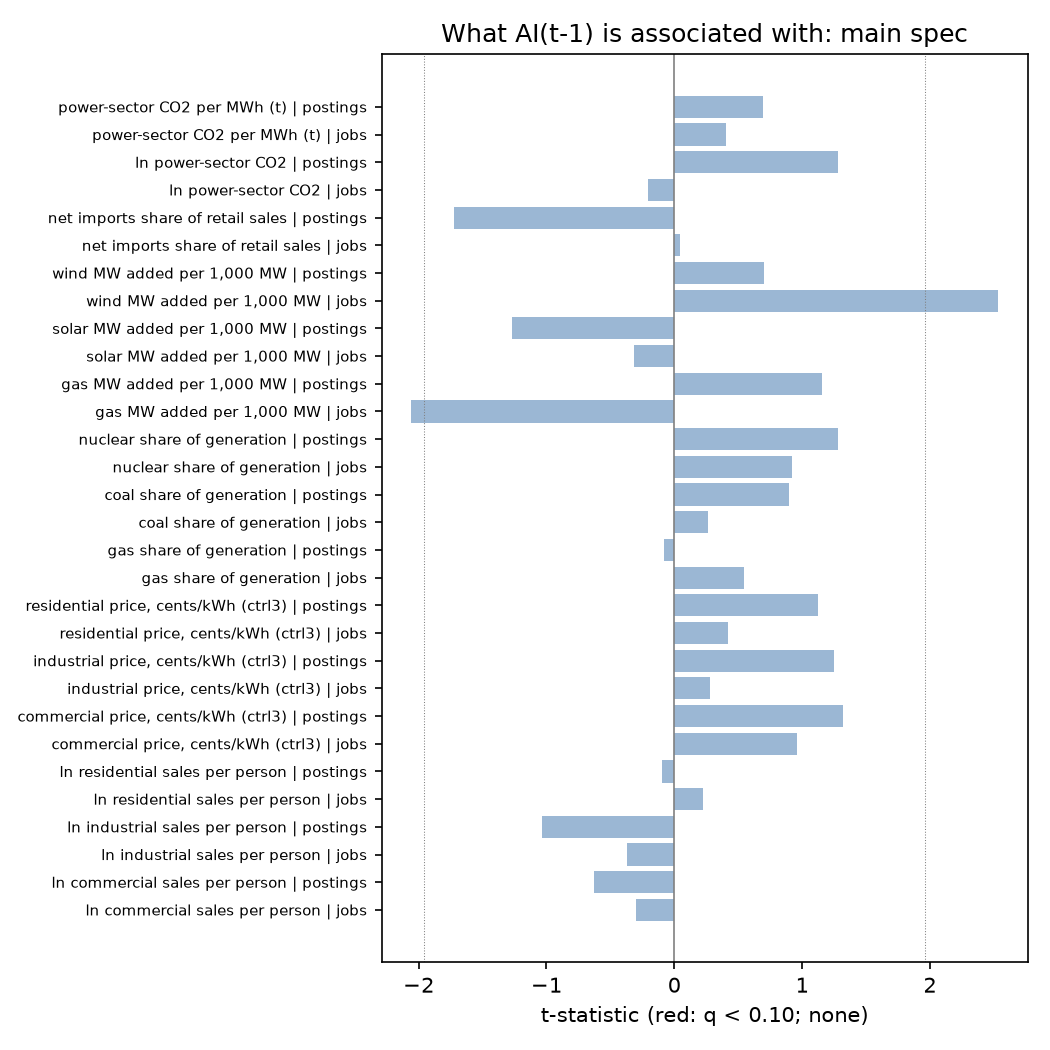

In [5]:
it = pd.read_csv(T + 's3_impact_table.csv'); display(it.drop(columns=['tag', 'note', 'lead_placebo', 'finding']))
display(pd.read_csv(T + 's3_restructured_classification.csv').round(1))
display(Image(F + 'fig_s3_impact_t.png', width=560))

**Reading:** nothing passes: the smallest q is 0.44, so no lead placebo or restructuring model ran. The nulls are fairly tight. One more data-center job per 1,000 workers goes with commercial sales per person between -2.9% and +2.1%, and with the gas share between -0.9 and +1.6 points.
So in 2015-2025 state data, AI growth isn't associated with detectable changes in sales, prices, the generation mix, imports or power-sector CO2.

## 4. Why did renewables grow nationally?

**Question:** what explains the common upward path, and is it AI?

**What we ran:** (1) year effects from the main two-way model (base 2015). (2) An **interim** drivers model: no year FE, with state RPS/CES targets, solar resource x solar LCOE, solar resource x ITC, 2015 gas share x Henry Hub, plus the national main effects, AI(t-1) and ctrl4. Wind cost and the PTC phase-down are missing because the LBNL wind file and CRS R43453 refuse scripted downloads (deviation X3). Resource is 2015 EIA capacity factors, since NREL was unreachable (deviation X4). (3) The AI coefficient with state FE only, with drivers, and with two-way FE.

$$Y_{st} = \mu_s + b_1 RPS_{st} + b_2 (CF^{sol}_s \times LCOE^{sol}_t) + b_4 (CF^{sol}_s \times ITC_t) + b_6 (gas_{s,2015} \times HH_t) + c'D_t + a\, AI_{s,t-1} + \gamma'\text{ctrl4}_{st} + \varepsilon_{st}$$

,year,solar_lcoe_2025usd_mwh,itc_pct,ptc_pct_of_full,hh_usd_mmbtu,us_dc_jobs_50,us_ai_postings_50
0,2015,121.36,30.0,NaN,2.62,296180.0,NaN
1,2016,93.97,30.0,NaN,2.52,300613.0,NaN
2,2017,94.75,30.0,NaN,2.99,312788.0,NaN
3,2018,75.95,30.0,NaN,3.15,332568.0,186277.0
4,2019,63.76,30.0,NaN,2.56,342873.0,321543.0
5,2020,54.95,26.0,NaN,2.03,360215.0,291890.0
6,2021,51.58,26.0,NaN,3.89,387137.0,397693.0
7,2022,50.53,30.0,100.0,6.45,465340.0,786018.0
8,2023,55.40,30.0,100.0,2.53,484431.0,454364.0
9,2024,58.41,30.0,100.0,2.19,482138.0,648427.0


,outcome,model,years,correlation,r_squared
0,renew_share,drivers-interim,2015-2025,0.814,0.662
1,ln_gen_wind,drivers-interim,2015-2025,0.840,0.706
2,ln_gen_solar,drivers-interim,2015-2025,0.765,0.585


,outcome,ai_measure,drivers-interim,statefe,twfe
0,ln_gen_solar,ai518210,+0.03438 (p=0.799),-0.04571 (p=0.794),+0.04204 (p=0.746)
1,ln_gen_solar,aipostp1000,+0.1587*** (p=0.003),+0.1229*** (p=0.007),-0.04603 (p=0.565)
2,ln_gen_wind,ai518210,-0.2012*** (p=0.007),-0.2173*** (p=0.008),-0.1805** (p=0.016)
3,ln_gen_wind,aipostp1000,+0.003233 (p=0.832),-0.001927 (p=0.869),-0.0477*** (p=0.002)
4,renew_share,ai518210,-0.01138* (p=0.071),-0.01242** (p=0.046),-0.01013 (p=0.100)
5,renew_share,aipostp1000,-0.0003017 (p=0.887),+0.0005188 (p=0.774),-0.005681* (p=0.089)


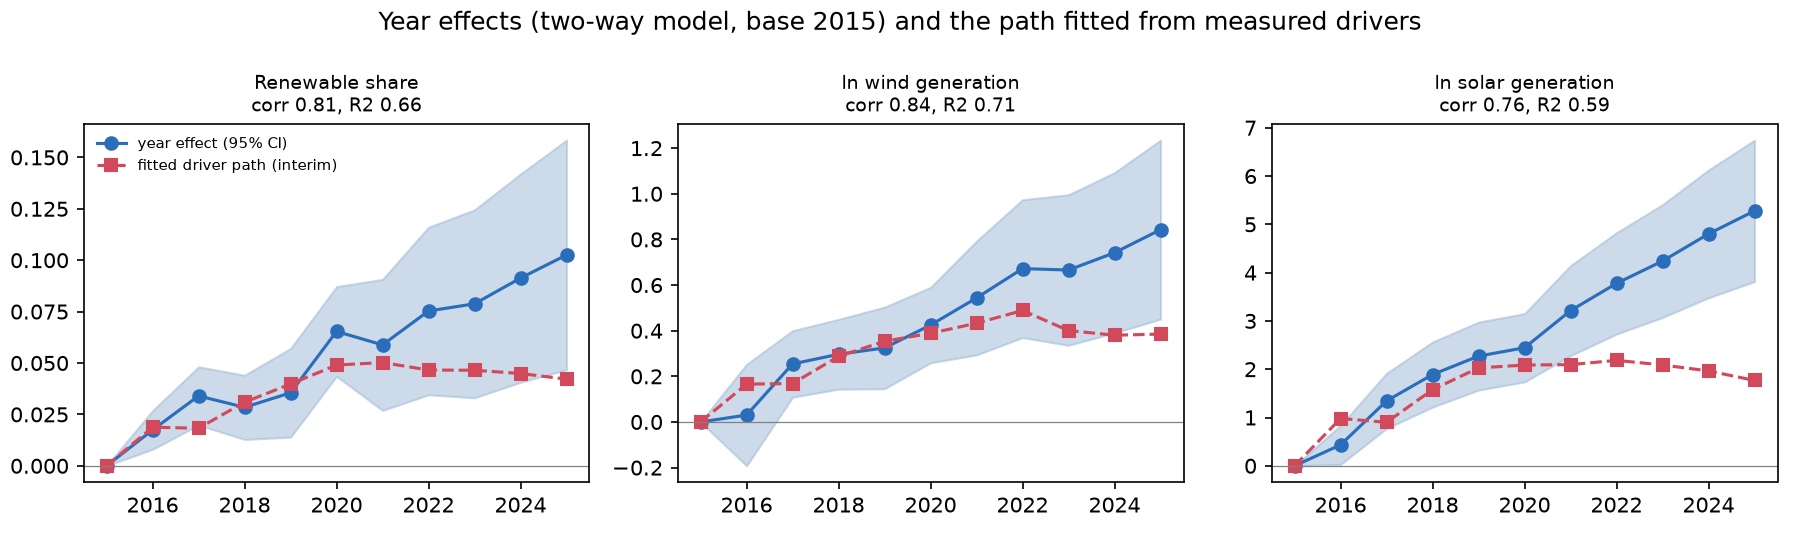

**What drove the national trend (interim; wind cost and the PTC pending).** Year effects from the two-way model rise steadily for all three outcomes (`s4_year_effects.csv`). Measured drivers that vary by state, namely state RPS/CES targets (LBNL), solar resource x utility-scale solar LCOE (LBNL Utility-Scale Solar, 2025 $/MWh, MW-weighted by commercial-operation year), solar resource x the solar ITC (P.L. 117-169, PDF pp. 98 and 103), and 2015 gas share x the Henry Hub price (EIA), reproduce much of that path: correlation 0.81 (R2 0.66) for renewable share, 0.84 (R2 0.71) for ln wind and 0.76 (R2 0.59) for ln solar, over 11 years. Solar LCOE fell from 121 to a low of 51 $/MWh (2022) before rising to 61, and the ITC stepped from 30% to 26% (2020-2021) and back to 30% under the IRA. AI isn't the national trend: with data-center jobs, the renewable-share coefficient is -0.0124 (p = 0.046) with state FE only, -0.0114 (p = 0.071) with drivers and -0.0101 (p = 0.100) with two-way FE, never positive. The exception is postings and ln solar generation: positive without year effects (+0.123, p = 0.007) and with interim drivers (+0.159, p = 0.003), and gone with year effects (-0.046, p = 0.565), so postings share a 2019-2025 trend with solar that the interim drivers don't capture. These are associations; the full model adds wind cost (LBNL Land-Based Wind Market Report) and the PTC phase-down (CRS R43453) once those files are downloaded by browser.


In [6]:
display(pd.read_csv(T + 's4_national_drivers.csv')[['year', 'solar_lcoe_2025usd_mwh', 'itc_pct', 'ptc_pct_of_full', 'hh_usd_mmbtu', 'us_dc_jobs_50', 'us_ai_postings_50']].round(2))
display(pd.read_csv(T + 's4_path_fit.csv')[['outcome', 'model', 'years', 'correlation', 'r_squared']].round(3))
display(pd.read_csv(T + 's4_ai_three_models.csv'))
display(Image(F + 'fig_s4_year_effects_drivers.png', width=950))
display(Markdown(open(T + 's4_writeup.md').read()))

**Reading:** measured drivers reproduce most of the national path even without wind cost and the PTC (correlation 0.76-0.84). With data-center jobs, AI is never positive for the renewable share, whether or not year effects are in.
Postings do track solar growth when year effects are left out, and that disappears once they're in. That pattern is a shared trend, not a state-level association.

## 5. A better AI measure

Pending: pass 2.